Import all the libraries needed.

In [1]:
# Import Python Libraries
import pandas as pd
from sklearn.naive_bayes import GaussianNB # Import Gaussian Naive Bayes for classification
from sklearn.model_selection import train_test_split # Import train_test_split function
from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

Reading data using pandas

In [2]:
# Read CSV file
df = pd.read_csv("HR_Employee_Retention.csv")
print(df.shape)
df.head()

(14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [3]:
df.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales                     object
salary                    object
dtype: object

Converting 'object' to 'numeric' before modelling

In [4]:
df['sales'] = df['sales'].astype('category')
df['salary'] = df['salary'].astype('category')
df.dtypes

satisfaction_level        float64
last_evaluation           float64
number_project              int64
average_montly_hours        int64
time_spend_company          int64
Work_accident               int64
left                        int64
promotion_last_5years       int64
sales                    category
salary                   category
dtype: object

In [5]:
df['sales_cat'] = df['sales'].cat.codes
df['salary_cat'] = df['salary'].cat.codes
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary,sales_cat,salary_cat
0,0.38,0.53,2,157,3,0,1,0,sales,low,7,1
1,0.80,0.86,5,262,6,0,1,0,sales,medium,7,2
2,0.11,0.88,7,272,4,0,1,0,sales,medium,7,2
3,0.72,0.87,5,223,5,0,1,0,sales,low,7,1
4,0.37,0.52,2,159,3,0,1,0,sales,low,7,1


In [6]:
df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary,sales_cat,salary_cat
0,0.38,0.53,2,157,3,0,1,0,sales,low,7,1
1,0.80,0.86,5,262,6,0,1,0,sales,medium,7,2
2,0.11,0.88,7,272,4,0,1,0,sales,medium,7,2
3,0.72,0.87,5,223,5,0,1,0,sales,low,7,1
4,0.37,0.52,2,159,3,0,1,0,sales,low,7,1
...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low,8,1
14995,0.37,0.48,2,160,3,0,1,0,support,low,8,1
14996,0.37,0.53,2,143,3,0,1,0,support,low,8,1
14997,0.11,0.96,6,280,4,0,1,0,support,low,8,1


In [7]:
df.dtypes

satisfaction_level        float64
last_evaluation           float64
number_project              int64
average_montly_hours        int64
time_spend_company          int64
Work_accident               int64
left                        int64
promotion_last_5years       int64
sales                    category
salary                   category
sales_cat                    int8
salary_cat                   int8
dtype: object

Feature Selection

In [8]:
#split dataset in features and target variable
feature_cols = ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours','time_spend_company','Work_accident','promotion_last_5years','sales_cat','salary_cat']
x = df[feature_cols] # Features
y = df.left # Target variable

In [9]:
# Checking missing values
df[df.isnull().any(axis=1)]

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary,sales_cat,salary_cat


In [10]:
# Split dataset into training set and test set
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [11]:
print("x_train.shape: ", x_train.shape)
print("y_train.shape: ", y_train.shape)
print("x_test.shape: ", x_test.shape)
print("y_test.shape: ", y_test.shape)

x_train.shape:  (11999, 9)
y_train.shape:  (11999,)
x_test.shape:  (3000, 9)
y_test.shape:  (3000,)


## Building Naive Bayes Model

In [12]:
# Create Naive Bayes classifer object
clf = GaussianNB()

# Train Naive Bayes Classifer
clf = clf.fit(x_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(x_test)

y_pred

array([0, 0, 1, ..., 1, 1, 1])

## Evaluating the model

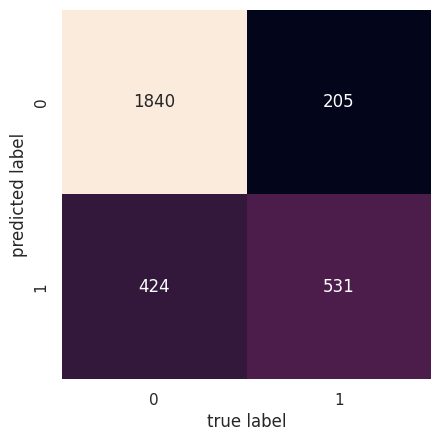

In [13]:
# Calculating Confusion Matrix
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(y_test, y_pred)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('true label')
plt.ylabel('predicted label');

In [14]:
# Showing the performance of the model. How often is the classifier correct? (accuracy)
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.81      0.85      2264
           1       0.56      0.72      0.63       736

    accuracy                           0.79      3000
   macro avg       0.73      0.77      0.74      3000
weighted avg       0.82      0.79      0.80      3000

